<a href="https://colab.research.google.com/github/valeriamarr/Practica.1-ValeriaMar/blob/main/14%20Cinem%C3%A1tica%20Inversa/Cinem%C3%A1tica_inversa_IK.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [46]:
!wget -nc 'https://raw.githubusercontent.com/Jegovila/SI2/refs/heads/main/14%20Cinem%C3%A1tica%20Inversa/Dibujar_Manipulador.py'

import numpy as np
import matplotlib.pyplot as plt
from Dibujar_Manipulador import dibujar_manipulador
from IPython import display

File ‘Dibujar_Manipulador.py’ already there; not retrieving.



Función de penalización

In [47]:
def Penalty(x, xl, xu):
    D = x.size
    z = 0

    for i in range(D):
        if x[i] < xl[i] or x[i] > xu[i]:
            z = z + 1

    return z

Función objetivo

In [48]:
f = lambda q: 0.5*np.sum((pd-p(q[0], q[1], q[2]))**2)
fp = lambda x, xl, xu: f(x)+beta*(Penalty(x,xl,xu))          # <----------------- Completar

Parámetros

In [50]:
animacion = 1
pd = [0.4, 0.4]
a_1 = 0.35
a_2 = 0.35
a_3 = 0.25

beta = 1000
xl = np.array([-np.pi,-np.pi,-np.pi])                    # <----------------- Completar
xu = np.array([np.pi,np.pi,np.pi])                    # <----------------- Completar


G = 10                    # <----------------- Completar
N = 60                   # <----------------- Completar
D = 3

F =  0.3                   # <----------------- Completar
CR =   0.7                 # <----------------- Completar

# DE

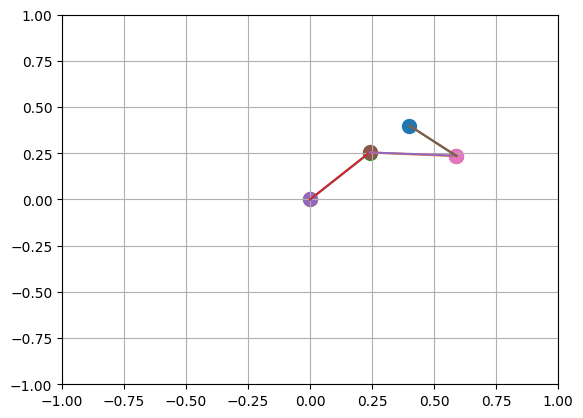

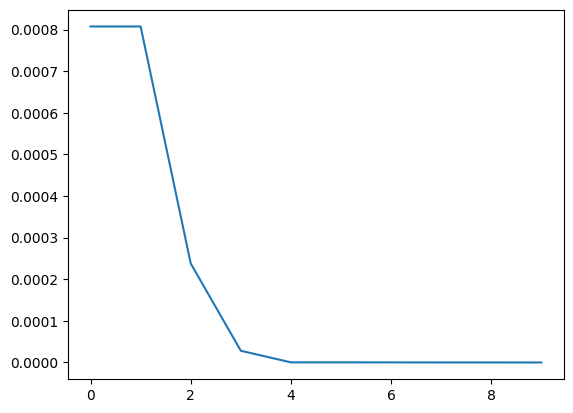

In [73]:
p = lambda theta_1, theta_2, theta_3: np.array([a_2*np.cos(theta_1 + theta_2) + a_1*np.cos(theta_1) + a_3*np.cos(theta_1 + theta_2 + theta_3),
                                                a_2*np.sin(theta_1 + theta_2) + a_1*np.sin(theta_1) + a_3*np.sin(theta_1 + theta_2 + theta_3)])

x = np.zeros((D, N))
fitness = np.zeros(N)

for i in range(N):
    x[:, i] = xl + (xu - xl) * np.random.rand(D)
    fitness[i] = fp(x[:, i], xl, xu)

fx_plot = np.zeros(G)

for n in range(G):
    if animacion:
        for i in range(0,N,50):
            display.display(plt.gcf())
            display.clear_output(wait=True)
            plt.clf()
            plt.scatter(pd[0], pd[1], marker='o', s=100)
            dibujar_manipulador(x[:, i])
            plt.grid(True)

    for i in range(N):
        # Mutación
        r1 = i
        while r1 == i:
            r1 = np.random.randint(N)

        r2 = r1
        while r2 == r1 or r2 == i:
            r2 = np.random.randint(N)

        best = np.argmin(fitness)

        v = x[:, best] + F * (x[:, r1] - x[:, r2])

        # Recombinación
        u = np.zeros(D)
        k = np.random.randint(D)

        for j in range(D):
            r = np.random.rand()

            if r <= CR or j == k:
                u[j] = v[j]
            else:
                u[j] = x[j, i]

        # Selección
        fitness_u = fp(u, xl, xu)

        if fitness_u < fitness[i]:
            x[:, i] = u.copy()
            fitness[i] = fitness_u

    fx_plot[n] = np.min(fitness)

igb = np.argmin(fitness)

q = x[:, igb]

theta_1 = q[0]
theta_2 = q[1]
theta_3 = q[2]

p_final = np.array([a_2*np.cos(theta_1 + theta_2) + a_1*np.cos(theta_1) + a_3*np.cos(theta_1 + theta_2 + theta_3),
                    a_2*np.sin(theta_1 + theta_2) + a_1*np.sin(theta_1) + a_3*np.sin(theta_1 + theta_2 + theta_3)])

display.display(plt.gcf())
display.clear_output(wait=True)
dibujar_manipulador(q)
plt.grid(True)

plt.show()
plt.plot(fx_plot)
plt.show()